# What Drives User Satisfaction with Productivity Applications?: Comparative Analysis of Apple App Store Reviews

This project analyzes customer reviews across six popular productivity apps available on the Apple App Store: Notion, Microsoft OneNote, Evernote, Todoist, Microsoft To Do, and Structured to assess the relationship between different aspects of user experience and customer satisfaction. 

Particularly, the project seeks to explore:
1. Which aspects of the user experience most strongly drive customer satisfaction across leading productivity apps?
2. Do those drivers differ between information management and task management tools?

#### Methodology
* Build a dataset of 3000 user reviews across 6 productivity apps
* Extract organic phrases and validate emotional tone with lexicon-based sentiment scoring against numerical star ratings
* Classify reviews into 7 core UX dimensions and run OLS regressions on star ratings
* Segment the dataset into Information Management (Notion, OneNote, Evernote) vs. Task Management (Todoist, Microsoft To Do, Structured) to compare category-specific UX drivers

#### Key Findings
- Negative UX friction penalizes star ratings 1.6× to 4.9× more severely than positive features reward them, led by Reliability (-1.14 stars), AI & Updates (-0.74 stars), Value & Pricing (-0.68 stars), and Functionality (-0.46 stars) versus Organization (+0.29 stars) and Usability (+0.23 stars).
- Segmenting the apps reveals that Information Management tools (Notion, OneNote, Evernote) are hurt most by Value & Pricing (-0.93 stars) and AI & Updates (-0.79 stars). In contrast, Task Management apps (Todoist, Microsoft To Do, Structured) are driven primarily by Reliability (-1.32 stars) and everyday Usability (+0.26 stars).

In [1]:
import requests
import pandas as pd
import re
from datetime import datetime, timezone
import time
import matplotlib.pyplot as plt

## Data Collection and Cleaning

The data for this project comes from publicly accessible Apple App Store customer reviews. The Apple RSS customer reviews feed provides information about individual reviews (review titles, review text, star ratings, dates, and application versions). The analysis focuses on the United States storefront to maintain consistency across applications.
<br>
<br>

Defining a function to locate the Apple App Store ID for each app in the sample:

In [93]:
app_list = ["Notion", "Microsoft OneNote", "Evernote", "Structured", "Todoist", "Microsoft To Do"]

def find_app_id(app_name, country="us"):
    """Given a search term, uses Apple's Search API to return similar app listings."""
    url = "https://itunes.apple.com/search"
    params = {"term": app_name, "entity": "software", "country": country, "limit": 10}

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    results = response.json()["results"]
   
    matches = []
    for app in results:
        matches.append({"search_term": app_name, "app_name": app.get("trackName"), "app_id": app.get("trackId"), "rating_count": app.get("userRatingCount"), "average_rating": app.get("averageUserRating"), "app_url": app.get("trackViewUrl")})
    return matches

app_dict = [find_app_id(app_name) for app_name in app_list]
app_matches = pd.DataFrame([match for sublist in app_dict for match in sublist])

In [94]:
apps = {"Notion": 1232780281, "Microsoft OneNote": 410395246, "Evernote": 281796108, "Structured": 1499198946, "Todoist": 572688855, "Microsoft To Do": 1212616790}

Collecting reviews for each app from the Apple App Store RSS feed and combining them into a dataset:

In [109]:
def get_app_reviews(app_name, app_id):
    """Returns up to 10 pages of the most recent reviews for an app on the Apple App Store."""
    reviews = []

    for page in range(1, 11):
        url = f"https://itunes.apple.com/us/rss/customerreviews/page={page}/id={app_id}/sortby=mostrecent/json"

        try:
            response = requests.get(url, timeout=30)
            response.raise_for_status()
            data = response.json()

        except requests.RequestException as error:
            print(f"Request failed for {app_name}, page {page}: {error}")
            break

        except ValueError:
            print(f"Could not read JSON for {app_name}, page {page}")
            break

        entries = data.get("feed", {}).get("entry", [])

        for entry in entries:
            if "im:rating" not in entry:
                continue

            reviews.append({
                "app_name": app_name,
                "app_id": app_id,
                "review_id": entry.get("id", {}).get("label"),
                "review_title": entry.get("title", {}).get("label"),
                "review_text": entry.get("content", {}).get("label"),
                "rating": entry.get("im:rating", {}).get("label"),
                "date": entry.get("updated", {}).get("label"),
                "app_version": entry.get("im:version", {}).get("label")
            })

        time.sleep(1)

    return reviews

all_reviews = []

for app_name, app_id in apps.items():
    reviews = get_app_reviews(app_name, app_id)
    all_reviews.extend(reviews)
    print(f"{app_name}: {len(reviews)} reviews collected")

df = pd.DataFrame(all_reviews)
print("Total reviews collected:", len(df))
df.head(1)

Notion: 500 reviews collected
Microsoft OneNote: 500 reviews collected
Evernote: 500 reviews collected
Structured: 500 reviews collected
Todoist: 500 reviews collected
Microsoft To Do: 500 reviews collected
Total reviews collected: 3000


,app_name,app_id,review_id,review_title,review_text,rating,date,app_version
0,Notion,1232780281,14827528892,Customization,I personally love using this app to organize my Original characters and to stay organized in general! But i would love if it would be possible to color a page directly. I seen you can color the blocks and add images and things but not customize the actual page itself!!,5,2026-11-23T22:55:18-07:00,1.7.356


Cleaning the raw dataset to prepare it for analysis:

In [213]:
print("\nRaw df summary:")
print(df.info())


Raw df summary:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   app_name      3000 non-null   str  
 1   app_id        3000 non-null   int64
 2   review_id     3000 non-null   str  
 3   review_title  3000 non-null   str  
 4   review_text   3000 non-null   str  
 5   rating        3000 non-null   str  
 6   date          3000 non-null   str  
 7   app_version   3000 non-null   str  
dtypes: int64(1), str(7)
memory usage: 187.6 KB
None


In [214]:
data = df.copy()

data["date"] = pd.to_datetime(df["date"], errors="coerce", utc=True)
data["rating"] = pd.to_numeric(data["rating"], errors="coerce")

data = data.drop_duplicates(subset=["app_name", "review_id"])

data["review"] = (data["review_title"].str.strip() + " " + data["review_text"].str.strip()).str.strip()
data = data[data["review"].str.len() > 0]
data["review"] = data["review"].str.replace(r"\s+", " ", regex=True).str.strip()

data["review_length"] = data["review"].str.split().str.len()
data["sentiment"] = data["rating"].map({
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"})
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.tz_localize(None).dt.to_period("M").astype(str)
data = data.sort_values("date", ascending=False)

data = data.reset_index(drop=True)
data.head()

,app_name,app_id,review_id,review_title,review_text,rating,date,app_version,review,review_length,sentiment,year,month
0,Structured,1499198946,14833036633,Creative ADHDer Heaven,"After years in the Navy, where someone told me what to do, when to do it, and how, I got out and started my own creative agency. Suddenly I had no idea where to start. With ADHD and executive functioning struggles, figuring out what's priority A, B, or C doesn't come naturally to me.\n\nStructured changed that. Since it connects to my AI, I can lay out my plans, my availability, and my priorities, and it helps me build my day around them. I spend less time planning and more time doing.\n\nI used to think a ""normal"" person shouldn't need help with this. But tools like this exist to make life easier. The military taught us to do everything the hard way. Not everything has to be hard. If you need more structure in your life, I'd recommend this.",5,2026-11-25 14:05:00+00:00,4.6.9,"Creative ADHDer Heaven After years in the Navy, where someone told me what to do, when to do it, and how, I got out and started my own creative agency. Suddenly I had no idea where to start. With ADHD and executive functioning struggles, figuring out what's priority A, B, or C doesn't come naturally to me. Structured changed that. Since it connects to my AI, I can lay out my plans, my availability, and my priorities, and it helps me build my day around them. I spend less time planning and more time doing. I used to think a ""normal"" person shouldn't need help with this. But tools like this exist to make life easier. The military taught us to do everything the hard way. Not everything has to be hard. If you need more structure in your life, I'd recommend this.",143,Positive,2026,2026-11
1,Evernote,281796108,14832717044,Ruined with Ads,"What used to be a great app has now been completely ruined with an insane amount of ads, forced click-throughs, relentless attempts to get you to commit to year-long subscriptions. Completely unusable at this point. I will be switching to a new application ASAP",1,2026-11-25 12:36:53+00:00,11.44.5,"Ruined with Ads What used to be a great app has now been completely ruined with an insane amount of ads, forced click-throughs, relentless attempts to get you to commit to year-long subscriptions. Completely unusable at this point. I will be switching to a new application ASAP",47,Negative,2026,2026-11
2,Microsoft OneNote,410395246,14832691946,Review,"Editing text is difficult, as with font, boldness, etc. This would make much more sense if it were similar to Word",3,2026-11-25 12:29:55+00:00,16.116.1,"Review Editing text is difficult, as with font, boldness, etc. This would make much more sense if it were similar to Word",22,Neutral,2026,2026-11
3,Structured,1499198946,14831318576,iOS 27,Hey can we get an update for the new Apple WatchOS? I updated it and now the app says (on my watch) that structure needs to be updated to work with the new operating system. I love this app it’s literally how I take care of myself lol. Really would love to have the watch compatibility back.,4,2026-11-25 03:37:07+00:00,4.6.9,iOS 27 Hey can we get an update for the new Apple WatchOS? I updated it and now the app says (on my watch) that structure needs to be updated to work with the new operating system. I love this app it’s literally how I take care of myself lol. Really would love to have the watch compatibility back.,59,Positive,2026,2026-11
4,Evernote,281796108,14830193433,They are nuts,I used to love this app in the old days. Then they got bigger and bigger and now it’s 200$ a year and I couldn’t find any of my old notes. Screw them! I lost hundreds of dollars in knitting patterns but I be pickled if I’ll be robbed to save it.,1,2026-11-24 20:31:23+00:00,11.44.5,They are nuts I used to love this app in the old days. Then they got bigger and bigger and now it’s 200$ a year and I couldn’t find any of my old notes. Screw them! I lost hundreds of dollars in knitting pat

In [234]:
data.to_csv("app_reviews_cleaned.csv", index=False)

The cleaned dataset contains 3,000 reviews from 6 apps with the following key variables:

| Column | Description |
| :--- | :--- |
| `app_name` | Application name. |
| `review_text` | Raw, uncleaned customer review body|
| `rating` | Numerical user star rating on a `1` to `5` scale (primary regression dependent variable). |
| `sentiment` | Rating-derived sentiment label (`Negative`: 1–2 stars, `Neutral`: 3 stars, `Positive`: 4–5 stars). |
| `review_length` | Word count of `review_text`, used as a regression control for review verbosity. |


## Exploratory Data Analysis
The cleaned dataset contains the 500 most recent reviews for each app. The reviews range from between late 2025 and early 2026 to late November 2026.

Reviews collected from high-velocity apps (e.g. Notion, Evernote) span a shorter time window, while lower-volume apps (such as Structured and Microsoft To Do) capture feedback over a longer time horizon. Including application fixed effects (`C(app_name)`) in the regression accounts for these baseline differences across apps.

Task management apps (Structured, Todoist) show ratings clustered heavily at 5 stars and thus high shares positive sentiment. Information management apps (Evernote, Notion, OneNote) and Microsoft To Do show more polarized distributions and a higher concentration of 1 star ratings. 
Because ratings are heavily concentrated at the extremes, identifying the specific friction points that trigger 1-star reviews is important to understanding differences in overall app performance.

Average review length ranges from 37.34 words (Microsoft OneNote) and 40.92 words (Microsoft To Do) up to 55.84 words (Evernote). Long reviews appear at both ends of the satisfaction spectrum, Evernote has the lowest average rating at 2.74 and generates the longest reviews while the top rated Todoist (3.85) and Structured (3.99) also on average have 51.4 and 49.3 word long reviews respectively. This suggests that both dissatisfied and satisfied users tend to write detailed reviews. Controlling for `review_length` in the subsequent regression isolates the effect of specific UX themes from review verbosity.

In [215]:
print("Dataset shape:", data.shape)
app_summary = data.groupby("app_name").agg(
    review_count=("review_id", "count"),
    average_rating=("rating", "mean"),
    median_rating=("rating", "median"),
    average_review_length=("review_length", "mean"),
    earliest_review=("date", "min"),
    latest_review=("date", "max"))
print("Summary by app:")
display(app_summary)

Dataset shape: (3000, 13)
Summary by app:


,review_count,average_rating,median_rating,average_review_length,earliest_review,latest_review
app_name,,,,,,
Evernote,500,2.738,2.0,55.840,2026-03-10 15:51:56+00:00,2026-11-25 12:36:53+00:00
Microsoft OneNote,500,3.042,3.0,37.338,2026-05-03 14:26:36+00:00,2026-11-25 12:29:55+00:00
Microsoft To Do,500,3.016,3.0,40.920,2025-08-19 11:29:16+00:00,2026-11-24 17:00:47+00:00
Notion,500,3.072,3.0,49.486,2026-02-23 04:34:07+00:00,2026-11-24 05:55:18+00:00
Structured,500,3.994,5.0,49.408,2026-03-06 05:48:23+00:00,2026-11-25 14:05:00+00:00
Todoist,500,3.848,5.0,51.148,2025-01-28 08:57:50+00:00,2026-11-23 21:01:31+00:00


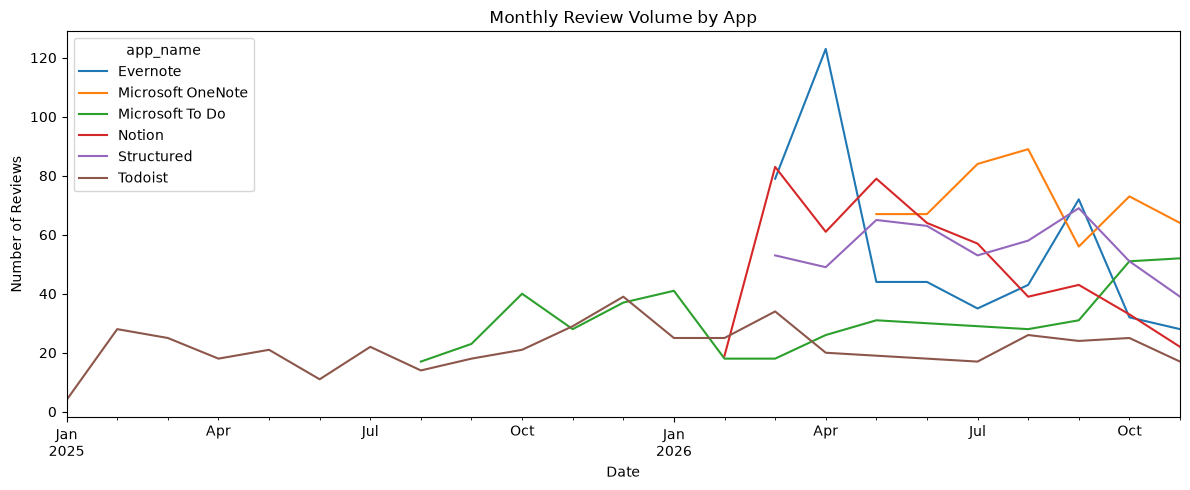

In [216]:
monthly_reviews = (data.set_index("date").groupby("app_name").resample("ME").size().unstack("app_name"))

monthly_reviews.plot(figsize=(12, 5))
plt.title("Monthly Review Volume by App")
plt.xlabel("Date")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

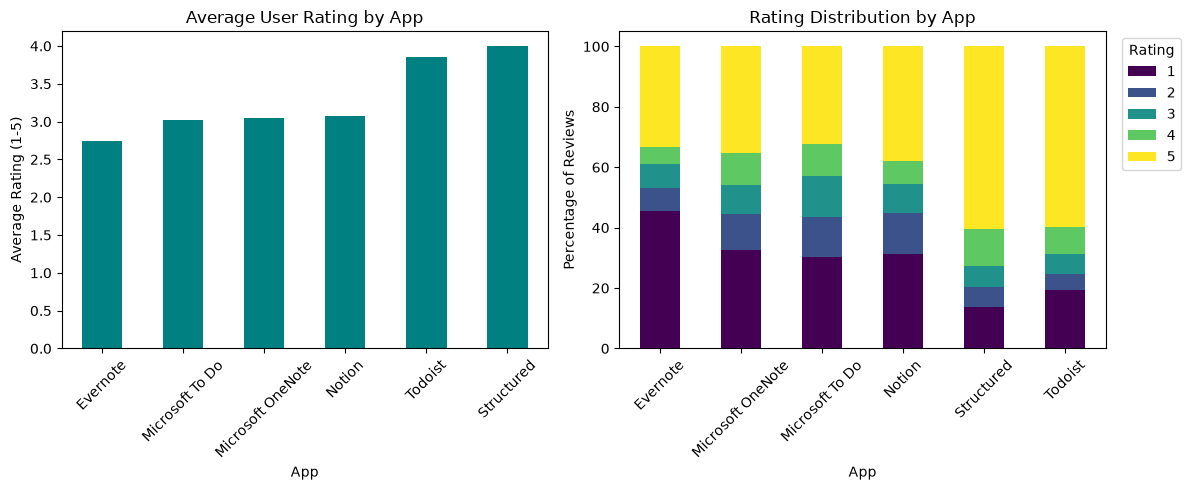

In [217]:
avg_rating = data.groupby("app_name")["rating"].mean().sort_values()
rating_counts = pd.crosstab(data["app_name"], data["rating"], normalize="index") * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

avg_rating.plot(kind="bar", ax=ax1, color="teal")
ax1.set_title("Average User Rating by App")
ax1.set_xlabel("App")
ax1.set_ylabel("Average Rating (1-5)")
ax1.tick_params(axis="x", rotation=45)

rating_counts.plot(kind="bar", stacked=True, ax=ax2, colormap="viridis")
ax2.set_title("Rating Distribution by App")
ax2.set_xlabel("App")
ax2.set_ylabel("Percentage of Reviews")
ax2.tick_params(axis="x", rotation=45)
ax2.legend(title="Rating", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

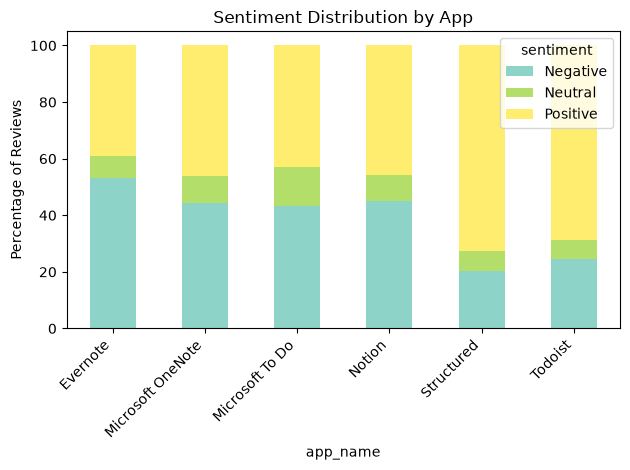

In [218]:
sentiment_counts = pd.crosstab(data["app_name"], data["sentiment"], normalize="index") * 100
sentiment_counts.plot(kind="bar", stacked=True, colormap="Set3")
plt.title("Sentiment Distribution by App")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

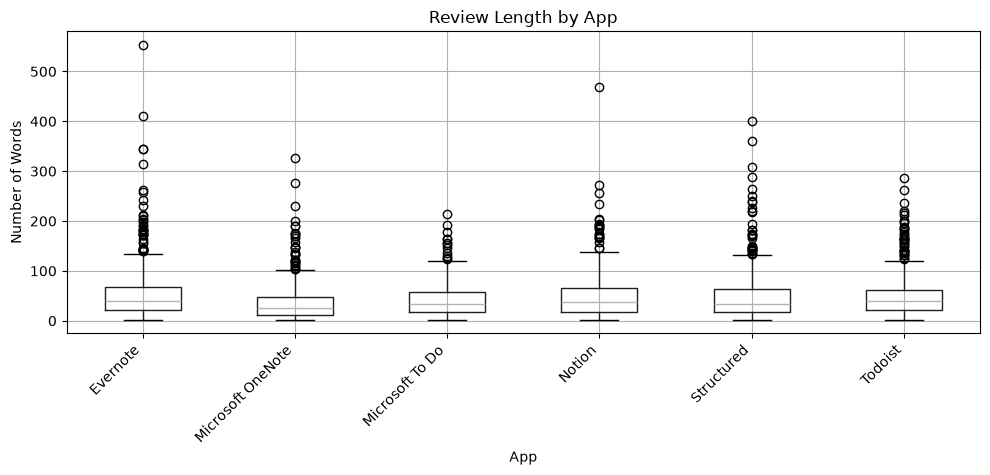

In [219]:
data.boxplot(column="review_length", by="app_name", figsize=(10, 5))
plt.title("Review Length by App")
plt.suptitle("")
plt.xlabel("App")
plt.ylabel("Number of Words")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Text Analysis and Sentiment Validation
Before regression analysis, user reviews were explored to identify recurring pain points and positive drivers from user language and validate whether written emotional tone in the reviews aligns with numerical star ratings.

Reviews were grouped by their rating-based `sentiment` label (`Positive` vs. `Negative`) and decomposed into two-word phrases (bigrams).

<br>

Normalizing `review_text` and removing low information words to create the column **`bigram_text`** for phrase mining:

In [220]:
import re
import contractions
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

#Removing specific words frequent in the reviews that provide no UX details and general stop words
custom_stop_words = {"app", "apps", "notion", "onenote", "microsoft", "evernote",
    "structured", "todoist", "todo", "apple", "use", "using", "used", "just", "like", "really", "make", "making", "made",
    "get", "getting", "got", "way", "thing", "things", "good", "great", "love",
    "loved", "best", "nice", "bad", "does", "did", "doing", "know", "sure", "want", "need", "highly", "recommend",
    "year", "ago", "long", "does", "single", "soon", "possible", "try", "game", "changer"}
stop_words = (set(ENGLISH_STOP_WORDS) | custom_stop_words) - {"not", "no", "never"}

def clean_text_bigram(text):
    text = str(text).lower()
    text = contractions.fix(text)
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = []
#Refining to merge common word variants in the dataset
    for w in text.split():
        if w in {"working", "works", "worked"}:
            w = "work"
        elif w in {"organized", "organizing"}:
            w = "organize"
        elif w in {"crashes", "crashing", "crashed"}:
            w = "crash"
#Turning plurals singular so frequency count is the same, e.g. task to tasks 
        elif len(w) > 3 and w.endswith("s") and not w.endswith(("ss", "us", "is", "he", "ay")):
            w = w[:-1]
        if w not in stop_words:
            words.append(w)
    return " ".join(words)

Word bigrams were counted across positive and negative reviews and ranked by their smoothed positive-to-negative frequency ratio:
$$\text{Positive Ratio} = \frac{\text{Positive Count} + 1}{\text{Negative Count} + 1}$$

The review text analysis revealed several UX patterns. Negative reviews frequently mention *"time open"*, *"not sync"*, *"price increase"*, *"pop ups"*, and *"ai feature"* while positive review terms include *"help organize"*, *"completed task"*, and *"pro version"*.

In [221]:
data["bigram_text"] = data["review_text"].apply(clean_text_bigram)
vec = CountVectorizer(ngram_range=(2, 2), min_df=8)
X = vec.fit_transform(data["bigram_text"])

bigram_df = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
bigram_df["sentiment"] = data["sentiment"].values

bigram_freq = bigram_df.groupby("sentiment").sum().T
bigram_freq.columns.name = None
bigram_freq["total"] = bigram_freq["Positive"] + bigram_freq["Negative"]
bigram_freq["pos_ratio"] = (bigram_freq["Positive"] + 1) / (bigram_freq["Negative"] + 1)

print("Positive UX Bigrams:")
display(bigram_freq[bigram_freq["total"] >= 10].sort_values("pos_ratio", ascending=False).head(12))
print("Negative UX Bigrams:")
display(bigram_freq[bigram_freq["total"] >= 10].sort_values("pos_ratio", ascending=True).head(12))

Positive UX Bigrams:


,Negative,Neutral,Positive,total,pos_ratio
help organize,0,1,29,29,30.0
stay organize,0,1,25,25,26.0
help stay,0,0,16,16,17.0
helped organize,0,0,12,12,13.0
completed task,0,0,11,11,12.0
daily life,0,0,10,10,11.0
day life,0,0,10,10,11.0
learning curve,0,1,10,10,11.0
help track,0,0,10,10,11.0
organize life,1,0,16,17,8.5


Negative UX Bigrams:


,Negative,Neutral,Positive,total,pos_ratio
time open,31,2,1,32,0.062500
new note,12,0,0,12,0.076923
pop ups,12,2,0,12,0.076923
no longer,33,8,2,35,0.088235
not worth,10,2,0,10,0.090909
waste time,16,3,1,17,0.117647
not sync,13,0,1,14,0.142857
crash time,12,4,1,13,0.153846
not ai,11,1,1,12,0.166667
not work,72,16,12,84,0.178082


To measure emotional tone independently from star ratings, each review was scored using VADER (Valence Aware Dictionary and sEntiment Reasoner). 

VADER was applied to the unclean review text to account for the sentiment weight of features like punctuation and degree words which were eliminated through text normalization. Compound sentiment scores (**`vader_score`**, ranging from `-1` to `+1`) were categorized into three categories: Negative (`<= -0.05`), Neutral (`-0.05` to `0.05`), and Positive (`>= 0.05`) and cross-tabulated against star ratings (`sentiment`) to verify alignment between the written feedback and numerical scores:

text_sentiment,Negative,Neutral,Positive
sentiment,,,
Negative,0.435,0.170,0.395
Neutral,0.296,0.100,0.604
Positive,0.060,0.123,0.817


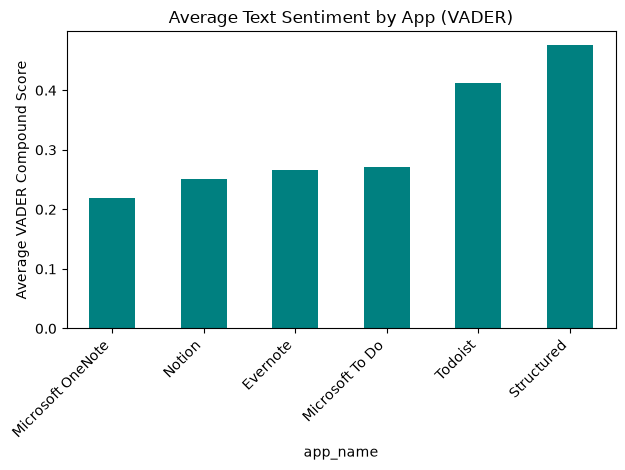

In [222]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()
data["vader_score"] = data["review_text"].fillna("").apply(lambda text: analyzer.polarity_scores(str(text))["compound"])
data["text_sentiment"] = pd.cut(data["vader_score"], bins=[-1.01, -0.05, 0.05, 1.01], labels=["Negative", "Neutral", "Positive"])

sentiment_comparison = pd.crosstab( data["sentiment"], data["text_sentiment"], normalize="index").round(3)
display(sentiment_comparison)

vader_by_app = data.groupby("app_name")["vader_score"].mean().sort_values()
vader_by_app.plot(kind="bar", color="teal")
plt.title("Average Text Sentiment by App (VADER)")
plt.ylabel("Average VADER Compound Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

There is high alignment between positive star ratings and positive review language. 81.7% of 4-5 star reviews use positive wording. Neutral, 3 star ratings have a 10% match with neutral text, as users leaving 3 stars usually frame feedback positively (60.4%) using "good app, but..." phrasing before mentioning their criticisms (29.6% negative match). Only 43.5% of 1–2 star reviews register as negative in VADER, while 39.5% score as positive and 17.0% as neutral.

The mismatch between negative star ratings and positive text sentiment scores from VADER could be a consequence of VADER underdetecting dissatisfaction when users leave polite, sarcastic, or nostalgic 1 star reviews (example below).

Because lexicon-based scoring under-detects polite or nostalgic dissatisfaction, numerical star ratings (`rating`) serve as a more reliable dependent variable for modeling customer satisfaction in the next section.

In [223]:
mismatched_reviews = data[
    (data["sentiment"] == "Negative") & 
    (data["text_sentiment"] == "Positive")
].sort_values(by="vader_score", ascending=False)

for idx, row in mismatched_reviews[["app_name", "rating", "vader_score", "review_text"]].head(1).iterrows():
    print(f"[{row['app_name']}] Rating: {row['rating']} | VADER: {row['vader_score']:.3f}")
    print(f"Review: {row['review_text']}\n" + "-"*60)


[Evernote] Rating: 1 | VADER: 0.990
Review: I used Evernote for 10–12 years and spent about eight of those meaning to find a better alternative.
Disclaimer: I always used the free plan, so yes, I’m complaining about a free service. But Evernote’s longstanding two-device limit never made upgrading feel like a value-add. It felt like ransom for the privilege of accessing my own notes across devices like it isn’t 2012.
I didn’t use it heavily: maybe 150 notes across 10 notebooks—recipes, clothing sizes, part numbers, quotations, and other small things I wanted to keep. I mostly treated it as a notebook that lived on my phone.
Today I opened Evernote to find a recipe and discovered the free tier had become dramatically more restrictive—roughly one notebook and 50 notes. I couldn’t even properly access my existing collection without accepting a seven-day trial that would begin billing about $250 per year.
So I spent the morning screenshotting notes, copying and pasting them elsewhere, and o

## UX Theme Classification and Regression Analysis

#### Dictionary-Based UX Theme Classification
Informed by the bigram text analysis, reviews were tagged across seven binary UX themes:
  1. **Usability** (ease of use, navigation, layout, confusion)
  2. **Functionality** (core features, missing capabilities, offline support)
  3. **Reliability** (bugs, crashes, slow loading/time to open, sync failures)
  4. **Organization** (notes, tasks, lists, calendars, staying organized)
  5. **Customization** (templates, widgets, themes, dark mode, flexibility)
  6. **Value & Pricing** (subscription cost, price increases, paywalls, free vs. pro versions)
  7. **AI & Updates** (AI features, redesigns, software updates, app bloat)

Tagging reviews across the seven UX themes and summarizing overall prevalence and app-level theme shares:

In [224]:
ux_themes = {
    "Usability": [
        "easy", "simple", "intuitive", "user friendly", "clean",
        "difficult", "confusing", "complicated", "clunky",
        "navigation", "interface", "layout", "design",
        "create new", "new note"],
    "Functionality": [
        "feature", "features", "function", "missing", "option", "options",
        "doesn't work", "does not work", "not working", "cannot", "can't",
        "unable", "support", "integration", "offline"],
    "Reliability": [
        "bug", "bugs", "crash", "crashes", "crashing", "glitch", "freeze",
        "freezing", "slow", "lag", "takes forever",
        "sync", "syncing", "synchronization", "won't sync", "doesn't sync",
        "error", "loading", "broken", "lost data", "data loss",
        "can't access", "cannot access", "won't open"],
    "Organization": [
        "organize", "organized", "organization", "stay organized",
        "help organize", "helped organize", "organize my life",
        "folder", "folders", "note", "notes", "task", "tasks",
        "completed task", "list", "lists", "project", "projects",
        "calendar", "schedule", "planner", "daily life",
        "categorize", "tag", "tags", "search", "keep track"],
    "Customization": [
        "customize", "customization", "customizable", "personalize", "personalization", "template", "templates",
        "widget", "widgets", "theme", "mode", "color", "settings", "flexible"],
    "Value & Pricing": [
        "price", "pricing", "price increase", "expensive", "subscription",
        "payment", "pay", "paid", "premium", "pro version", "free",
        "free version", "cost", "paywall", "not worth", "refund",
        "charge", "tier", "plan"],
    "AI & Updates": [
        "ai", "ai feature", "ai features", "artificial intelligence",
        "update", "updates", "updated", "new version", "redesign",
        "bloat", "bloated", "no longer", "used to be"]
}

In [225]:
theme_patterns = {
    theme: re.compile(r"\b(?:" + "|".join(re.escape(kw) for kw in keywords) + r")\b", flags=re.IGNORECASE)
    for theme, keywords in ux_themes.items()
}

def id_themes(text):
    text = contractions.fix(str(text))
    return {
        theme: int(bool(pattern.search(text)))
        for theme, pattern in theme_patterns.items()
    }

#Allows for running this cell twice:
data = data.drop(columns=[c for c in ux_themes.keys() if c in data.columns])

theme_df = pd.DataFrame(data["review_text"].apply(id_themes).tolist(), index=data.index)
data = pd.concat([data, theme_df], axis=1)
theme_summary = pd.DataFrame({
    "review_count": data[list(ux_themes.keys())].sum(),
    "pct_reviews": (data[list(ux_themes.keys())].mean() * 100).round(1),
    "avg_rating_when_mentioned": [data.loc[data[t] == 1, "rating"].mean() for t in ux_themes.keys()],
    "avg_vader_when_mentioned": [data.loc[data[t] == 1, "vader_score"].mean() for t in ux_themes.keys()]
}).sort_values("review_count", ascending=False).round(3)

display(theme_summary)


,review_count,pct_reviews,avg_rating_when_mentioned,avg_vader_when_mentioned
Organization,1336,44.5,3.445,0.435
Functionality,866,28.9,2.836,0.342
Value & Pricing,543,18.1,2.783,0.362
AI & Updates,500,16.7,2.400,0.185
Usability,497,16.6,3.569,0.474
Reliability,432,14.4,2.111,0.122
Customization,210,7.0,3.457,0.472


,Usability,Functionality,Reliability,Organization,Customization,Value & Pricing,AI & Updates
app_name,,,,,,,
Evernote,13.6,32.4,9.8,46.6,1.6,42.0,24.8
Microsoft OneNote,13.4,28.0,19.4,39.8,4.2,2.8,9.4
Microsoft To Do,14.6,27.2,28.8,50.6,8.8,3.8,11.6
Notion,14.2,31.8,16.0,27.4,10.6,10.0,31.4
Structured,21.2,23.8,5.4,47.6,7.0,31.0,12.0
Todoist,22.4,30.0,7.0,55.2,9.8,19.0,10.8


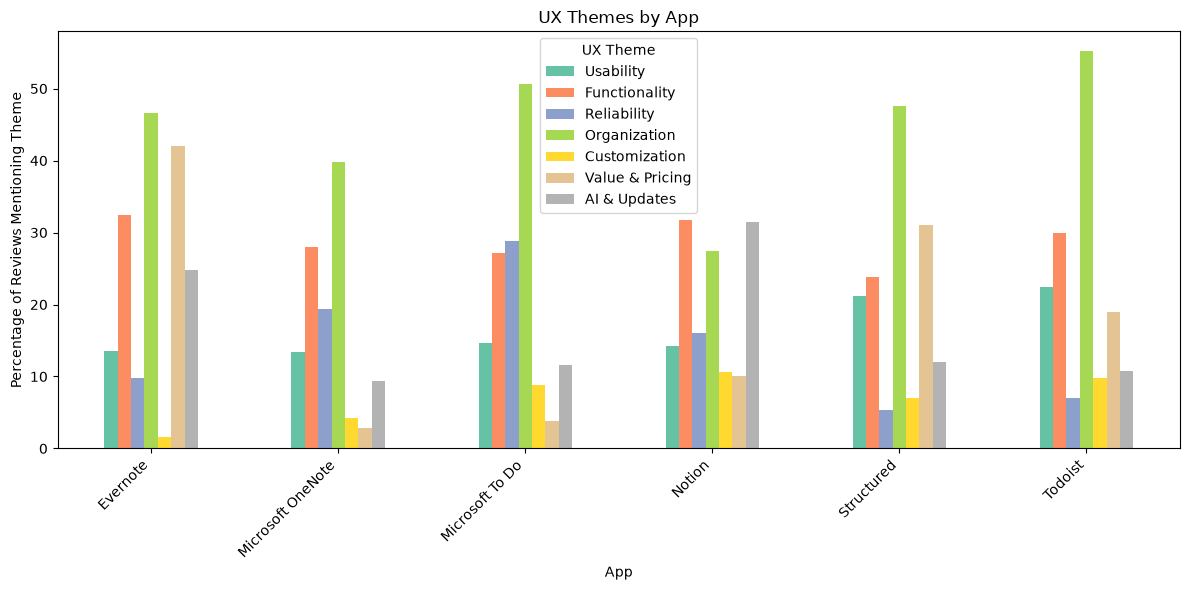

In [226]:
theme_by_app = data.groupby("app_name")[list(ux_themes.keys())].mean() * 100
display(theme_by_app.round(1))

theme_by_app.plot(kind="bar", figsize=(12, 6), colormap="Set2")
plt.title("UX Themes by App")
plt.xlabel("App")
plt.ylabel("Percentage of Reviews Mentioning Theme")
plt.xticks(rotation=45, ha="right")
plt.legend(title="UX Theme")
plt.tight_layout()
plt.show()

Organization is the most frequently discussed dimension (44.5% of reviews, 3.45 avg rating when mentioned), while Reliability (14.4%, 2.11 avg rating) and AI & Updates (16.7%, 2.40 avg rating) appear less frequently but coincide with the lowest star ratings.

Mention rates alone capture the topics users discuss but not the direction or magnitude of a UX theme's impact on satisfaction. This is especially true when a single review mentions multiple themes simultaneously, for example praising Functionality but complaining about Reliability. Notably, both Evernote (42%) and Structured (31%) show high rates of Value & Pricing mentions despite sitting at opposite ends of the rating spectrum (2.74 vs. 3.99 avg rating).

#### Pooled OLS Regression
To isolate the marginal star-rating impact of each UX dimension while holding all other themes constant, an Ordinary Least Squares (OLS) regression was estimated with heteroskedasticity-robust standard errors (HC3) to account for bounded, bimodal star ratings and control variables for review length and app fixed effects to isolate the independent impact of each UX dimension:

$$\text{Rating}_i = \beta_0 + \sum_{k=1}^{7} \beta_k \text{Theme}_{ik} + \gamma \text{ReviewLength}_i + \alpha_{\text{App}} + \varepsilon_i$$

Estimating the pooled OLS regression model on star ratings:

In [227]:
import statsmodels.formula.api as smf

regression_df = data.copy()
clean_theme_cols = {}
for theme in ux_themes.keys():
    clean_name = re.sub(r"[^a-z0-9]+", "_", theme.lower()).strip("_")
    clean_theme_cols[theme] = clean_name

regression_df = regression_df.rename(columns=clean_theme_cols)
regression_df["review_length"] = regression_df["review_text"].fillna("").str.split().str.len()

theme_variables = " + ".join(clean_theme_cols.values())
formula = f"rating ~ {theme_variables} + review_length + C(app_name)"

model = smf.ols(formula=formula, data=regression_df).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.208
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     78.46
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          1.61e-179
Time:                        16:34:37   Log-Likelihood:                -5548.1
No. Observations:                3000   AIC:                         1.112e+04
Df Residuals:                    2986   BIC:                         1.121e+04
Df Model:                          13                                         
Covariance Type:                  HC3                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercep

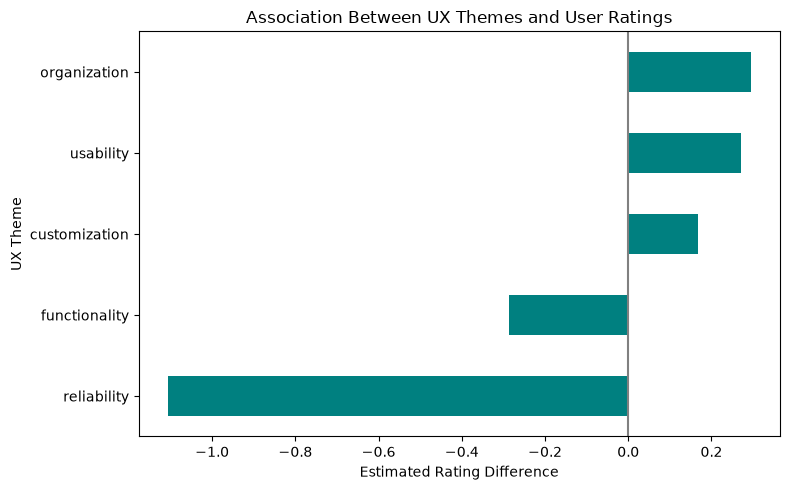

In [228]:
regression_results = regression_results.loc[regression_results.index.isin([t.lower().replace(" ", "_") for t in ux_themes])]
regression_results["coefficient"].plot(kind="barh", figsize=(8, 5), color="teal")
plt.axvline(0, color="gray")
plt.title("Association Between UX Themes and User Ratings")
plt.xlabel("Estimated Rating Difference")
plt.ylabel("UX Theme")
plt.tight_layout()
plt.show()

**Pooled Regression Results**


- The pooled OLS specification explains 20.8% of the variance in user star ratings and is jointly significant at the 1% level (F(13, 2986) = 78.46, p < 0.001). This confirms that structured UX themes derived from the review text meaningfully explain customer satisfaction across competing productivity apps.
- As illustrated in the coefficient bar chart above, ceteris paribus, Reliability is associated with the largest decrease in expected rating (-1.1358 stars, p < 0.001), followed by AI & Updates (-0.7449 stars, p < 0.001), Value & Pricing (-0.6798 stars, p < 0.001), and Functionality (-0.4587 stars, p < 0.001). This demonstrates that technical stability, pricing friction, and disruptive product changes could be primary drivers of customer dissatisfaction.
- Conversely, Organization (+0.2862 stars, p < 0.001) and Usability (+0.2319 stars, p = 0.002) show statistically significant positive partial effects at the 1% level, while Customization (+0.1962 stars, p = 0.062) is marginally significant at the 10% level.
- Comparing coefficient magnitudes demonstrates that negative UX friction penalizes expected ratings around 1.6x to 4.9x more heavily than positive UX dimensions increase them.
- The coefficient on review_length (+0.0008, p = 0.332) is not statistically significant, indicating that there is no linear association between review verbosity and star rating conditional on review content.
- Relative to the omitted reference category (Evernote, baseline intercept = 3.2579 stars, p < 0.001), Structured (+0.9703 stars, p < 0.001), Todoist (+0.7492 stars, p < 0.001), and Notion (+0.2744 stars, p = 0.012) show positive baseline rating shifts, whereas Microsoft OneNote (+0.0412 stars, p = 0.712) and Microsoft To Do (+0.0961 stars, p = 0.380) show no significant difference from Evernote. This indicates that even after accounting for UX complaints and praise, dedicated task-oriented tools maintain a higher baseline satisfaction level than legacy note-taking apps.

#### Category Segmentation: Information Management vs. Task Management
Because users rely on heavy knowledge bases differently than daily to-do lists, the dataset was segmented into two categories to test whether satisfaction drivers differ by the core functional purpose of the app:
| Category | App | Primary Function |
| :--- | :--- | :--- |
| Information Management | Notion, Microsoft OneNote, Evernote | Capturing, storing, organizing, and retrieving information |
| Task Management | Todoist, Microsoft To Do, Structured | Planning activities, managing responsibilities, scheduling, and tracking tasks |
<br>

**Information Management (n = 1,500; Reference App = Evernote):**
$$\text{Rating}_i = \beta_0 + \sum_{k=1}^{7} \beta_k \text{Theme}_{ik} + \gamma \text{ReviewLength}_i + \alpha_1 \text{OneNote}_i + \alpha_2 \text{Notion}_i + \varepsilon_i$$

**Task Management (n = 1,500; Reference App = Microsoft To Do):**
$$\text{Rating}_i = \beta_0 + \sum_{k=1}^{7} \beta_k \text{Theme}_{ik} + \gamma \text{ReviewLength}_i + \delta_1 \text{Structured}_i + \delta_2 \text{Todoist}_i + \varepsilon_i$$

<br>
Estimating segmented OLS regressions and comparing coefficients across categories:

In [229]:
info_apps = ["Notion", "Microsoft OneNote", "Evernote"]
task_apps = ["Todoist", "Microsoft To Do", "Structured"]

regression_df["category"] = regression_df["app_name"].apply(
    lambda x: "Info Management" if x in info_apps else "Task Management"
)

theme_vars = " + ".join(clean_theme_cols.values())
#sets Microsoft To Do as the reference var for task apps and Evernote for info apps
formula_seg = f"rating ~ {theme_vars} + review_length + C(app_name)"

model_info = smf.ols(formula_seg, data=regression_df[regression_df["category"] == "Info Management"]).fit(cov_type="HC3")
model_task = smf.ols(formula_seg, data=regression_df[regression_df["category"] == "Task Management"]).fit(cov_type="HC3")

comparison_table = pd.DataFrame({
    "Info_Mgmt_Coef": model_info.params,
    "Info_Mgmt_Pval": model_info.pvalues,
    "Task_Mgmt_Coef": model_task.params,
    "Task_Mgmt_Pval": model_task.pvalues
}).round(4)

display(comparison_table)


,Info_Mgmt_Coef,Info_Mgmt_Pval,Task_Mgmt_Coef,Task_Mgmt_Pval
C(app_name)[T.Microsoft OneNote],-0.0815,0.4987,NaN,NaN
C(app_name)[T.Notion],0.1896,0.1086,NaN,NaN
C(app_name)[T.Structured],NaN,NaN,0.7697,0.0000
C(app_name)[T.Todoist],NaN,NaN,0.5796,0.0000
Intercept,3.3701,0.0000,3.3895,0.0000
ai_updates,-0.7907,0.0000,-0.6033,0.0000
customization,0.2575,0.1440,0.1276,0.3263
functionality,-0.5318,0.0000,-0.3857,0.0001
organization,0.3255,0.0004,0.2455,0.0041
reliability,-0.9734,0.0000,-1.3233,0.0000


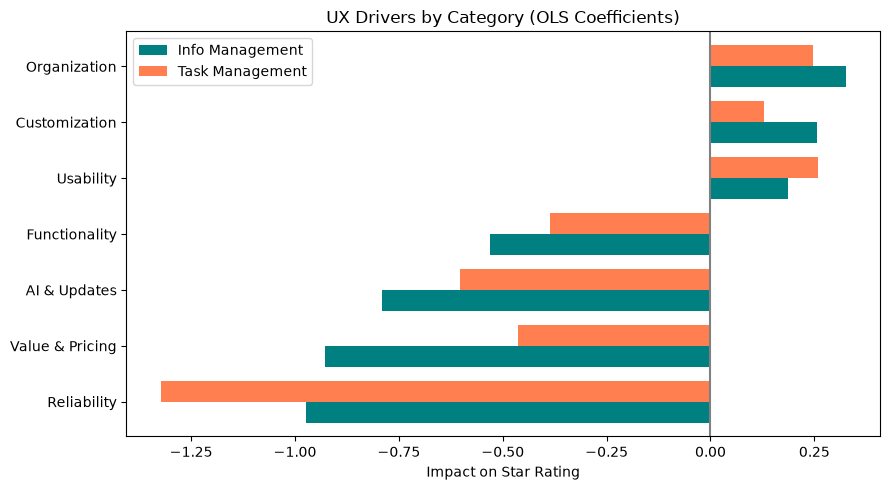

In [230]:
theme_plot = comparison_table.loc[list(clean_theme_cols.values()), ["Info_Mgmt_Coef", "Task_Mgmt_Coef"]]
theme_plot.index = list(clean_theme_cols.keys())
theme_plot = theme_plot.sort_values("Info_Mgmt_Coef")

ax = theme_plot.plot(kind="barh", figsize=(9, 5), color=["teal", "coral"], width=0.75)
ax.legend(["Info Management", "Task Management"])
ax.axvline(0, color="gray")
ax.set_xlabel("Impact on Star Rating")
ax.set_title("UX Drivers by Category (OLS Coefficients)")
plt.tight_layout()
plt.show()

**Segmented Regression Results:**
- Estimating separate OLS models across Information Management and Task Management reveals significant heterogeneity in partial slope coefficients.
- Among Information Management apps, Value & Pricing (-0.9277 stars, p < 0.001) and AI & Updates (-0.7907 stars, p < 0.001) have substantially larger negative marginal effects than in Task Management (-0.4625 stars, p < 0.001 and -0.6033 stars, p < 0.001, respectively). Information Management Apps also display a steeper negative penalty for Functionality (-0.5318 vs. -0.3857 stars, both p < 0.001).
- Within Task Management apps, Reliability has the largest negative partial effect (-1.3233 stars vs. -0.9734 stars in Information Management, both p < 0.001). Usability (+0.2594 stars, p = 0.008) is statistically significant at the 1% level, unlike in Information Management (+0.1864 stars, p = 0.124 - not statistically significant).
- Organization is positive and statistically significant at the 1% level in both Information Management (+0.3255 stars, p < 0.001) and Task Management (+0.2455 stars, p = 0.004), while Customization is statistically insignificant in both subsamples (p = 0.144 and p = 0.326).
- Conditional on UX dimensions, app fixed effects within Information Management become jointly insignificant relative to Evernote, indicating that observed rating disparities among these apps are largely accounted for by the included UX covariates. In contrast, Structured (+0.7697 stars, p < 0.001) and Todoist (+0.5796 stars, p < 0.001) retain statistically significant positive fixed effects relative to Microsoft To Do.


## App Specific UX Driver Decomposition
To pinpoint the concrete mechanisms behind each broad UX theme inside individual apps, per-app TF-IDF logistic regression predictors were extracted alongside a heatmap of specific sub-issue counts and average star ratings across apps.

<br>

Decomposing positive and negative predictors and sub-issue ratings by individual apps:

In [231]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Omitting neutral (3-star) ratings for contrast
binary_df = data[data["sentiment"].isin(["Positive", "Negative"])].copy()
binary_df["is_positive"] = (binary_df["sentiment"] == "Positive").astype(int)

app_drivers = []

for app in sorted(binary_df["app_name"].unique()):
    sub = binary_df[binary_df["app_name"] == app]
    
    # TF-IDF on bigram text without low info stop words
    tfidf_ignore = {"not", "no", "thank", "thanks", "thought", "guess", "amazing", "useful", "tool", "far"}
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=4, max_features=500, stop_words=list(tfidf_ignore))
    X = vec.fit_transform(sub["bigram_text"])
    y = sub["is_positive"]
    
    # logistic regression with l2 regularization
    clf = LogisticRegression(C=1.0, max_iter=1000)
    clf.fit(X, y)
    
    feature_names = vec.get_feature_names_out()
    coefs = clf.coef_[0]
    
    top_pos_idx = coefs.argsort()[-6:][::-1]
    top_neg_idx = coefs.argsort()[:6]
    
    app_drivers.append({ "App": app,
        "Top Positive Predictors (4-5 stars)": ", ".join(feature_names[i] for i in top_pos_idx),
        "Top Negative Predictors (1-2 stars)": ", ".join(feature_names[i] for i in top_neg_idx)
    })

app_drivers_df = pd.DataFrame(app_drivers)
pd.set_option("display.max_colwidth", None)
display(app_drivers_df)


,App,Top Positive Predictors (4-5 stars),Top Negative Predictors (1-2 stars)
0,Evernote,"organize, easy, alway, life, daily, stay","price, free, ads, subscription, account, pop"
1,Microsoft OneNote,"easy, organize, help, business, awesome, para","crash, account, useless, notebook, difficult, issue"
2,Microsoft To Do,"help, organize, day, track, easy, daily","crash, ios, sync, slow, update, doe"
3,Notion,"life, organize, planning, personal, helpful, project","ai, ipad, update, doe work, unusable, bug"
4,Structured,"organize, easy, help, day, life, schedule","pay, repeat, paid, subscription, pro, mac"
5,Todoist,"organize, life, easy, track, simple, helpful","deleted, crash, data, doe, wanted, notification"


Using the predictors to look for specific prevalent issues in the review text for each app:

In [232]:
specific_issues = {
    "Price Hike / Subscription Cost": r"\b(?:price|pricing|price increase|expensive|cost|not worth|subscription|cancel)\b",
    "Free Tier Limits / Paywall / Ads": r"\b(?:free|free plan|free version|paywall|pop up|pop ups|popup|popups|ad|ads|advert|limit|limited|tier|repeat|recurring|pay|paid|pro)\b",
    "Sync & Data/Task Loss": r"\b(?:sync|syncing|synchronization|won't sync|doesn't sync|lost data|data loss|delete|deleted|missing tasks|disappeared)\b",
    "Crashes, Slow Load & Platform Bugs": r"\b(?:slow|lag|time to open|takes forever|crash|crashes|crashing|freeze|freezing|bug|bugs|ios|ipad|unusable)\b",
    "Account & Login Friction": r"\b(?:account|login|log in|sign in|password|locked out)\b",
    "AI Rollout": r"\b(?:ai|ai feature|ai features|artificial intelligence)\b",
    "Disruptive Updates / Redesign": r"\b(?:update|updates|updated|new version|redesign|no longer|used to be)\b",
}

records = []
for app in sorted(data["app_name"].unique()):
    app_df = data[data["app_name"] == app]
    for issue, pattern in specific_issues.items():
        mask = app_df["review_text"].fillna("").str.contains(pattern, flags=re.IGNORECASE, regex=True)
        n = mask.sum()
        # Filtering out outlier cases when an issue was mentioned < 5 times 
        if n >= 5:
            records.append({"App": app, "Specific Issue": issue, "Review Count": n,
                "Percent of App": round(n / len(app_df) * 100, 1),
                "Avg Rating": round(app_df.loc[mask, "rating"].mean(), 2)
            })

app_issue_df = pd.DataFrame(records).sort_values(["App", "Avg Rating"])
display(app_issue_df)

,App,Specific Issue,Review Count,Percent of App,Avg Rating
4,Evernote,Account & Login Friction,26,5.2,1.27
1,Evernote,Free Tier Limits / Paywall / Ads,127,25.4,1.54
6,Evernote,Disruptive Updates / Redesign,78,15.6,1.83
0,Evernote,Price Hike / Subscription Cost,148,29.6,1.89
2,Evernote,Sync & Data/Task Loss,27,5.4,1.93
3,Evernote,"Crashes, Slow Load & Platform Bugs",44,8.8,2.05
5,Evernote,AI Rollout,53,10.6,2.15
11,Microsoft OneNote,Account & Login Friction,27,5.4,1.74
7,Microsoft OneNote,Price Hike / Subscription Cost,6,1.2,2.17
10,Microsoft OneNote,"Crashes, Slow Load & Platform Bugs",108,21.6,2.21


Creating heatmap showing which exact problems affect which apps:

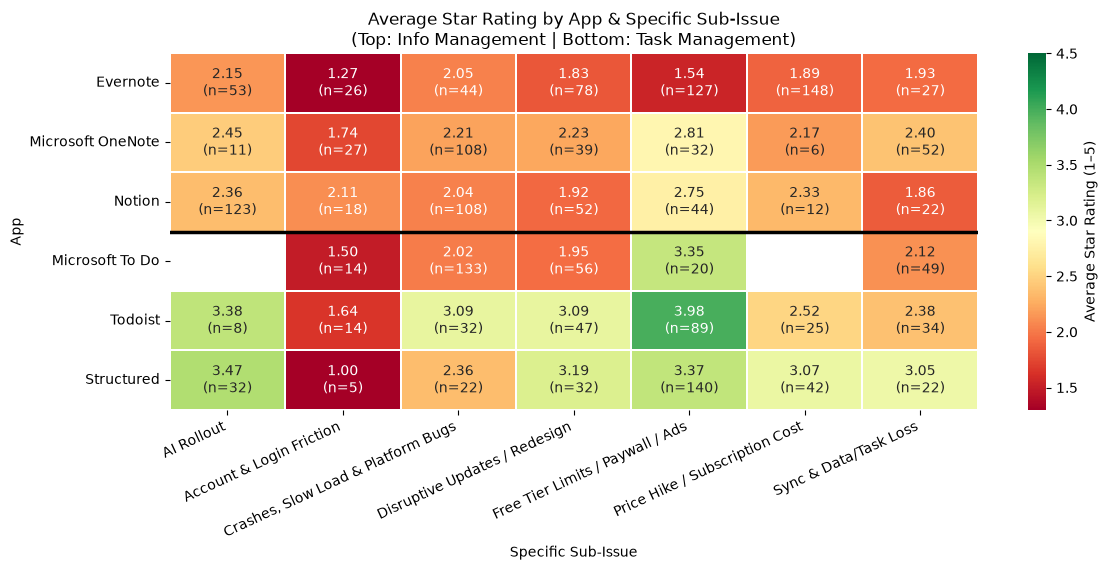

In [233]:
import seaborn as sns

# Pivotting avg ratings and review counts
rating_pivot = app_issue_df.pivot(index="App", columns="Specific Issue", values="Avg Rating")
count_pivot = app_issue_df.pivot(index="App", columns="Specific Issue", values="Review Count")

# Ordering apps by Info Management (top 3) vs. Task Management (bottom 3)
ordered_apps = ["Evernote", "Microsoft OneNote", "Notion", "Microsoft To Do", "Todoist", "Structured"]
rating_pivot = rating_pivot.reindex(ordered_apps)
count_pivot = count_pivot.reindex(ordered_apps)
# Adding cell annotations
annot_matrix = pd.DataFrame(index=rating_pivot.index, columns=rating_pivot.columns, dtype=object)
for app in rating_pivot.index:
    for issue in rating_pivot.columns:
        val = rating_pivot.loc[app, issue]
        cnt = count_pivot.loc[app, issue]
        if pd.notna(val):
            annot_matrix.loc[app, issue] = f"{val:.2f}\n(n={int(cnt)})"
        else:
            annot_matrix.loc[app, issue] = "N/A\n(n<5)"

plt.figure(figsize=(12, 5.8))
ax = sns.heatmap(rating_pivot, annot=annot_matrix, fmt="", cmap="RdYlGn", vmin=1.3, vmax=4.5, cbar_kws={"label": "Average Star Rating (1–5)"}, linewidths=1.2, linecolor="white")
ax.axhline(3, color="black", linewidth=2.5)

plt.title("Average Star Rating by App & Specific Sub-Issue\n(Top: Info Management | Bottom: Task Management)",)
plt.xlabel("Specific Sub-Issue")
plt.ylabel("App")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#### App-Specific Sub-Issue Findings:
Combining per-app TF-IDF predictors with the sub-issue heatmap clarifies the pain points driving dissatisfaction across each product:
- **Evernote (2.74 overall avg rating)**: Dissatisfaction is heavily concentrated in monetization and update friction. Price Hike / Subscription Cost appears in 29.6% of reviews (n = 148, 1.89 avg stars), Free Tier Limits / Paywall / Ads in 25.4% (n = 127, 1.54 avg stars; TF-IDF: price, free, ads, subscription, account, pop), and Disruptive Updates / Redesign in 15.6% (n = 78, 1.83 avg stars).
- **Notion (3.07 overall avg rating)**: Negative reviews are led by AI Rollout mentions in 24.6% of reviews (n = 123, 2.36 avg stars; TF-IDF: ai) and Crashes, Slow Load & Platform Bugs in 21.6% (n = 108, 2.04 avg stars; TF-IDF: ai, ipad, update, doe work, unusable, bug), alongside Disruptive Updates / Redesign (10.4%, n = 52, 1.92 avg stars). Satisfied users praise personal life planning (life, organize, planning, personal).
- **Microsoft OneNote (3.04 overall avg rating)**: Pain points center on Crashes, Slow Load & Platform Bugs (21.6%, n = 108, 2.21 avg stars; TF-IDF: crashe, issue), Sync & Data/Task Loss (10.4%, n = 52, 2.40 avg stars), and Account & Login Friction (5.4%, n = 27, 1.74 avg stars; TF-IDF: crash, account, useless, notebook, difficult, issue), while positive reviews highlight the ease of use and business utility (easy, organize, business).
- **Microsoft To Do (3.02 overall avg rating)**: 26.6% of reviews cite Crashes, Slow Load & Platform Bugs (n = 133, 2.02 avg stars; TF-IDF: crash,  ios, slow), 11.2% cite Disruptive Updates / Redesign (n = 56, 1.95 avg stars), and 9.8% cite Sync & Data/Task Loss (n = 49, 2.12 avg stars).
- **Todoist (3.85 overall avg rating)**: Satisfied users consistently praise simplicity and daily tracking (organize, life, easy, track, simple), while negative reviews stem from Sync & Data/Task Loss (6.8%, n = 34, 2.38 avg stars; TF-IDF: deleted, data), Price Hike / Subscription Cost (5.0%, n = 25, 2.52 avg stars), and Account & Login Friction (2.8%, n = 14, 1.64 avg stars), alongside occasional crashes and notification issues (TF-IDF: crash, notification).
- **Structured (3.99 overall avg rating)**: Although Structured achieves the highest overall rating in the sample, 28% of reviews mention Free Tier Limits / Paywall / Ads (n = 116, 3.26 avg stars), with TF-IDF predictors (pay, paid, repeat, pro, subscription) showing that negative feedback concentrates around core features like recurring tasks (repeat) being gated behind the paid tier.
- Across nearly every app, Account & Login Friction, even while relatively infrequent (1.0%–5.4% of reviews), produces the lowest average star ratings in the entire heatmap (1.00 to 2.11 stars), suggesting that authentication lockouts trigger immediate 1 star backlash whenever they occur.

## Key Takeways and Limitations

#### Actionable Product Recommendations
- Reliability has the largest negative effect in the overall model (-1.14 stars) and hurts daily Task Management apps even more (-1.32 stars). Teams should focus on fixing crashes, syncing bugs, and device-specific problems before adding new features. This is especially relevant for iOS crashes and slow loading in Microsoft To Do (26.6% of reviews, 2.02 avg stars), iPad bugs in Notion (21.6%, 2.04 avg stars), and deleted tasks or sync failures in Todoist (6.8%, 2.38 avg stars). Furthermore, because Account & Login Friction causes the lowest ratings across every app (1.00 to 2.11 stars), making the sign-in process and password resets smoother is an easy way to prevent 1 star reviews.
- Value & Pricing complaints (-0.68 stars overall, -0.93 stars in Information Management) sharply lower ratings when users feel pushed into paying. Evernote (29.6% price/subscription mentions at 1.89 avg stars, 22.2% paywall/ad mentions at 1.54 avg stars) can reduce user loss by cutting back on ads and softening free tier limits. Similarly, Structured (4.00 overall avg rating) can keep its top rating by leaving basic tools—like recurring tasks—free instead of locking them behind a paid plan (23.2% of reviews, 3.26 avg stars).
- AI & Updates (-0.74 stars overall, -0.79 stars in Information Management) hurts ratings almost as much as price hikes. In Notion, where 24.6% of reviews mention AI (2.36 avg stars) and 10.4% mention disruptive updates (1.92 avg stars), AI tools should stay optional and out of the way of basic note-taking functions. Across both Evernote (15.6% disruptive updates, 1.83 avg stars) and Microsoft To Do (11.2%, 1.95 avg stars), updates should keep familiar layouts intact and let users opt out of major changes.
- Information Management and Task Management apps succeed for different reasons. Task Management apps (Todoist, Structured, Microsoft To Do) should focus on speed and simple everyday Usability (+0.26 stars, p = 0.008), while Information Management apps (Notion, Microsoft OneNote, Evernote) should focus on strong Organization (+0.33 stars, p < 0.001) and fast search. Users will accept a more complex interface for note-taking as long as the app stays fast, reliable, and fairly priced.
  
#### Limitations And Future Directions
  Keyword and regular expression matching accurately captures explicit mentions of UX dimensions and sub-issues, but may miss implicit phrasing, nuanced context, or sarcasm (as shown by VADER sentiment score vs. rating score analysis). Applying transformer-based embeddings or zero shot classification in future work could capture edge cases. As user star ratings are bounded values (1 to 5) rather than continuous outcomes, estimating an ordered logit or probit model would provide a useful non-linear robustness check alongside the HC3-robust linear OLS. Additionally, the sample of App Store reviews captured feedback from vocal users in the most recent release windows, so regression estimates reflect conditional associations rather than strict causal effects. Pairing review text with longitudinal retention or data from across different platforms (Google Play Store/Microsoft Store) would further strengthen causal inference.